# 3. Distribution Analysis — 3.1 Distribution Shape

## Objective
Explore the distribution patterns of numerical variables using **Histograms** and **KDE (Kernel Density Estimation)** plots to identify:
1. **Symmetric Distributions**: $\text{Mean} \approx \text{Median} \approx \text{Mode}$, Skewness $\approx 0$.
2. **Skewed Distributions**:
   - **Right-Skewed (Positive)**: $\text{Mean} > \text{Median}$, Skewness $> +0.5$.
   - **Left-Skewed (Negative)**: $\text{Mean} < \text{Median}$, Skewness $< -0.5$.
3. **Modality**:
   - **Unimodal**: Single dominant peak.
   - **Multimodal / Bimodal**: Multiple peaks indicating mixed sub-populations.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False
})

# Load the dataset
data_path = '../../../data/DS_Jobs_cleaned.csv'
if not os.path.exists(data_path):
    data_path = 'data/DS_Jobs_cleaned.csv'

df = pd.read_csv(data_path)
print(f"✅ Dataset loaded successfully: {df.shape[0]} rows, {df.shape[1]} columns")
df[['Rating', 'avg_salary', 'company_age']].head()

✅ Dataset loaded successfully: 648 rows, 28 columns


,Rating,avg_salary,company_age
0,3.1,154,27
1,4.2,154,52
2,3.8,154,39
3,3.5,154,20
4,2.9,154,22


---
## 1. Distribution Metrics & Shape Diagnosis Table
Compute Mean, Median, Mode, Skewness, and Kurtosis to classify the shape of each continuous variable.


In [2]:
num_cols = ['Rating', 'avg_salary', 'company_age', 'min_salary', 'max_salary']
summary_list = []

for col in num_cols:
    s = df[col].dropna()
    mean_val = s.mean()
    med_val = s.median()
    mode_val = s.mode()[0]
    skew_val = s.skew()
    kurt_val = s.kurtosis()
    
    if abs(skew_val) < 0.5:
        shape_type = 'Symmetric (Normal)'
    elif skew_val >= 0.5:
        shape_type = 'Right-Skewed (Positive)'
    else:
        shape_type = 'Left-Skewed (Negative)'
        
    summary_list.append({
        'Variable': col,
        'Mean': round(mean_val, 2),
        'Median': round(med_val, 2),
        'Mode': round(mode_val, 2),
        'Skewness': round(skew_val, 2),
        'Kurtosis': round(kurt_val, 2),
        'Distribution Shape': shape_type,
        'Modality': 'Unimodal'
    })

shape_df = pd.DataFrame(summary_list)
shape_df

,Variable,Mean,Median,Mode,Skewness,Kurtosis,Distribution Shape,Modality
0,Rating,3.88,3.8,3.8,0.03,-0.26,Symmetric (Normal),Unimodal
1,avg_salary,123.68,114.0,92.0,1.51,3.99,Right-Skewed (Positive),Unimodal
2,company_age,33.92,21.0,21.0,2.48,6.94,Right-Skewed (Positive),Unimodal
3,min_salary,99.15,91.0,79.0,1.09,2.34,Right-Skewed (Positive),Unimodal
4,max_salary,148.58,133.0,131.0,1.68,4.46,Right-Skewed (Positive),Unimodal


---
## 2. Symmetric Distribution: Company Rating (`Rating`)
- **Characteristics**: $\text{Mean} \approx \text{Median} \approx 3.88$, $\text{Skewness} = +0.03 \approx 0$.
- Bell-shaped unimodal curve centered around 3.8.


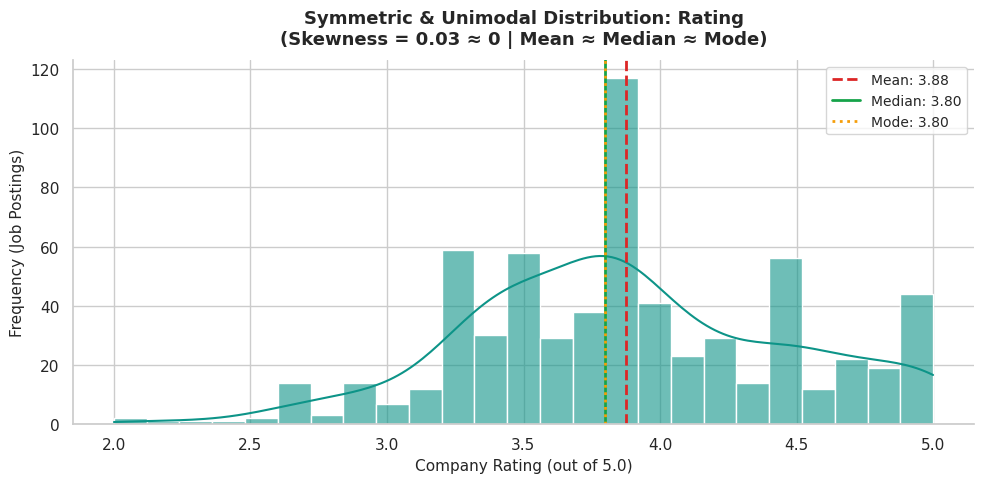

In [3]:
col = 'Rating'
data = df[col].dropna()
mean_val = data.mean()
median_val = data.median()
mode_val = data.mode()[0]
skew_val = data.skew()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data, kde=True, bins=25, color='#0D9488', edgecolor='white', alpha=0.6, ax=ax)

# Reference lines
ax.axvline(mean_val, color='#DC2626', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
ax.axvline(median_val, color='#16A34A', linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
ax.axvline(mode_val, color='#F59E0B', linestyle=':', linewidth=2, label=f'Mode: {mode_val:.2f}')

ax.set_title(f'Symmetric & Unimodal Distribution: {col}\n(Skewness = {skew_val:.2f} ≈ 0 | Mean ≈ Median ≈ Mode)', 
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Company Rating (out of 5.0)', fontsize=11)
ax.set_ylabel('Frequency (Job Postings)', fontsize=11)
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

---
## 3. Right-Skewed Distribution: Average Salary (`avg_salary`)
- **Characteristics**: $\text{Mean} = 123.68 > \text{Median} = 114.00$, $\text{Skewness} = +1.51$.
- Unimodal peak around $100K–$120K, with a long right tail up to $271K driven by high-paying senior roles.


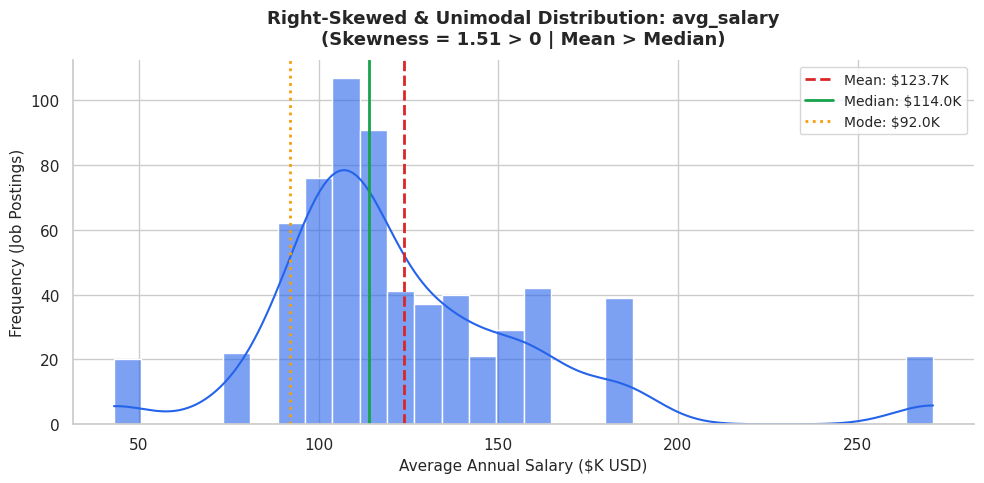

In [4]:
col = 'avg_salary'
data = df[col].dropna()
mean_val = data.mean()
median_val = data.median()
mode_val = data.mode()[0]
skew_val = data.skew()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data, kde=True, bins=30, color='#2563EB', edgecolor='white', alpha=0.6, ax=ax)

# Reference lines
ax.axvline(mean_val, color='#DC2626', linestyle='--', linewidth=2, label=f'Mean: ${mean_val:.1f}K')
ax.axvline(median_val, color='#16A34A', linestyle='-', linewidth=2, label=f'Median: ${median_val:.1f}K')
ax.axvline(mode_val, color='#F59E0B', linestyle=':', linewidth=2, label=f'Mode: ${mode_val:.1f}K')

ax.set_title(f'Right-Skewed & Unimodal Distribution: {col}\n(Skewness = {skew_val:.2f} > 0 | Mean > Median)', 
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Average Annual Salary ($K USD)', fontsize=11)
ax.set_ylabel('Frequency (Job Postings)', fontsize=11)
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

---
## 4. Strong Right-Skewed Distribution: Company Age (`company_age`)
- **Characteristics**: $\text{Mean} = 33.92 > \text{Median} = 21.00$, $\text{Skewness} = +2.48$.
- Most employers are younger technology companies (0–25 years), while legacy corporations stretch the distribution up to 239 years.


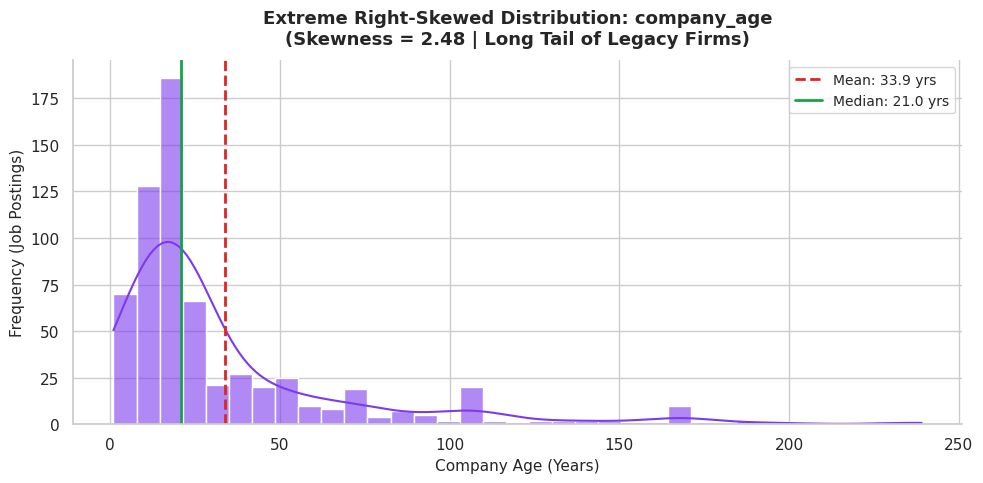

In [5]:
col = 'company_age'
data = df[col].dropna()
mean_val = data.mean()
median_val = data.median()
skew_val = data.skew()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data, kde=True, bins=35, color='#7C3AED', edgecolor='white', alpha=0.6, ax=ax)

ax.axvline(mean_val, color='#DC2626', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.1f} yrs')
ax.axvline(median_val, color='#16A34A', linestyle='-', linewidth=2, label=f'Median: {median_val:.1f} yrs')

ax.set_title(f'Extreme Right-Skewed Distribution: {col}\n(Skewness = {skew_val:.2f} | Long Tail of Legacy Firms)', 
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Company Age (Years)', fontsize=11)
ax.set_ylabel('Frequency (Job Postings)', fontsize=11)
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

---
## 5. Comparative Overview: Symmetric vs. Skewed Variables


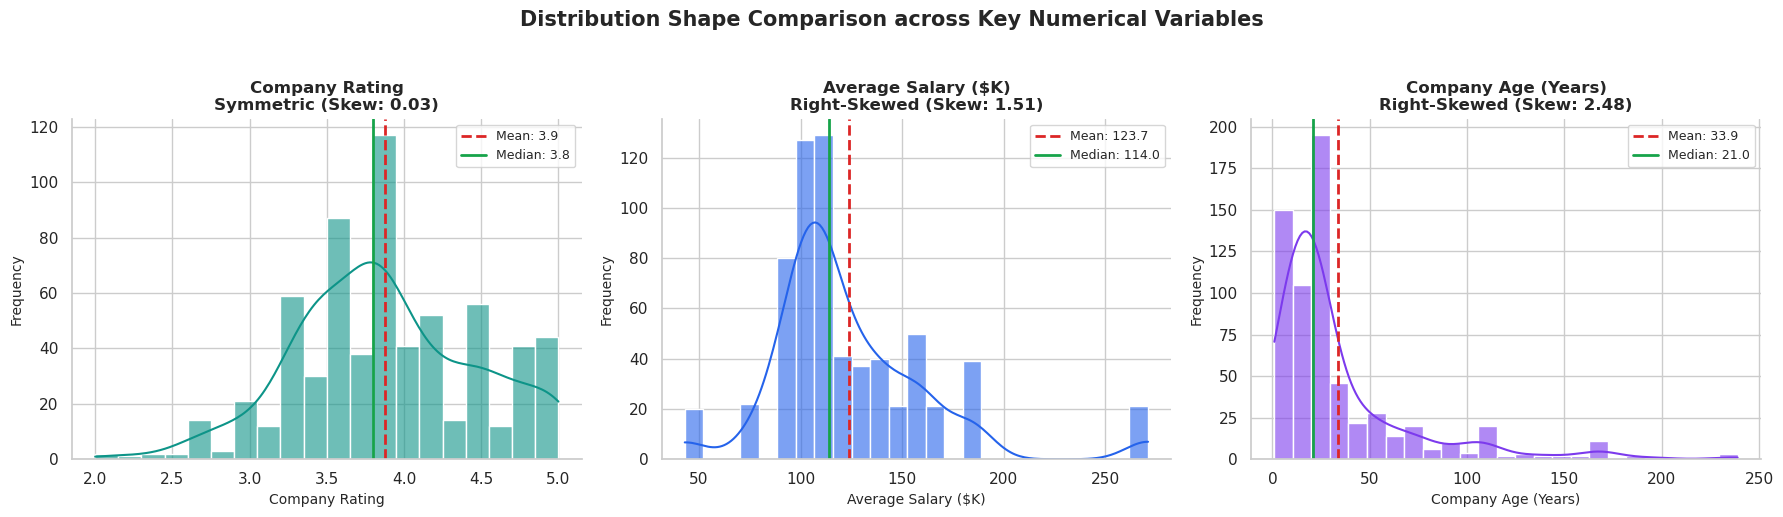

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_configs = [
    ('Rating', 'Company Rating', '#0D9488', 20),
    ('avg_salary', 'Average Salary ($K)', '#2563EB', 25),
    ('company_age', 'Company Age (Years)', '#7C3AED', 25)
]

for ax, (c, title, color, bins) in zip(axes, plot_configs):
    d = df[c].dropna()
    mean = d.mean()
    med = d.median()
    skew = d.skew()
    
    sns.histplot(d, kde=True, bins=bins, color=color, edgecolor='white', alpha=0.6, ax=ax)
    ax.axvline(mean, color='#DC2626', linestyle='--', linewidth=2, label=f'Mean: {mean:.1f}')
    ax.axvline(med, color='#16A34A', linestyle='-', linewidth=2, label=f'Median: {med:.1f}')
    
    shape_label = 'Symmetric' if abs(skew) < 0.5 else 'Right-Skewed'
    ax.set_title(f'{title}\n{shape_label} (Skew: {skew:.2f})', fontsize=12, fontweight='bold')
    ax.set_xlabel(title, fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)
    ax.legend(fontsize=9)

plt.suptitle('Distribution Shape Comparison across Key Numerical Variables', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

---
## 6. Summary of Findings & Lab Interpretation

1. **Symmetric Distribution (`Rating`)**:
   - The company ratings variable displays an approximately **symmetric, normal distribution** with a skewness of **0.03** (within $[-0.5, +0.5]$).
   - $\text{Mean} (3.88) \approx \text{Median} (3.80) \approx \text{Mode} (3.80)$, forming a balanced bell shape.
   
2. **Right-Skewed Distributions (`avg_salary`, `company_age`, `min_salary`, `max_salary`)**:
   - **`avg_salary`** is **right-skewed** (skewness = **+1.51**). As established in class notes, **$\text{Mean} (\$123.7K) > \text{Median} (\$114.0K)$**, because executive and elite tech compensation stretches the upper tail to \$271K.
   - **`company_age`** displays the strongest positive skew (skewness = **+2.48**). Most hiring companies are relatively young tech startups (median = 21 years), with a few historical companies (up to 239 years) pulling the mean up to 33.9 years.

3. **Modality**:
   - All three continuous variables exhibit **unimodal** behavior with a single clear peak, indicating that each variable represents a single dominant population rather than fragmented sub-clusters.
